In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r '/content/drive/MyDrive/NhanDien' '/content/'

In [ ]:
# Install pycocotools for COCO dataset handling
!pip install pycocotools

# torchvision, and torch are usually pre-installed in Colab, but ensure they are up-to-date
# You might need to install specific versions if issues arise
# !pip install torch torchvision

print("Dependencies installed.")

Dependencies installed.


In [ ]:
import os
import json
from PIL import Image

import torch
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator

from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from pycocotools.coco import COCO

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random # Import random for RandomHorizontalFlip

# Define paths
ROOT_DIR = '/content/NhanDien'
TRAIN_IMG_DIR = os.path.join(ROOT_DIR, 'train') # Corrected to 'train'
TRAIN_ANN_FILE = os.path.join(ROOT_DIR, 'train', '_annotations.coco.json') # Corrected to 'train'
VAL_IMG_DIR = os.path.join(ROOT_DIR, 'test')
VAL_ANN_FILE = os.path.join(ROOT_DIR, 'test', '_annotations.coco.json')


class COCODataset(Dataset):
    def __init__(self, root, annotation, transforms=None):
        self.root = root
        self.transforms = transforms
        self.coco = COCO(annotation)
        # Ensure imgToAnns has keys, if not, there are no annotations for images
        self.ids = list(self.coco.imgToAnns.keys())
        if not self.ids:
            # If no annotated images, try getting all image IDs if any exist in info
            self.ids = list(self.coco.imgs.keys())
            print(f"Warning: No images with annotations found. Using all {len(self.ids)} image IDs.")

        cat_ids = self.coco.getCatIds()
        self.categories = {cat['id']: cat['name'] for cat in self.coco.loadCats(cat_ids)}
        self.class_to_idx = {name: id for id, name in self.categories.items()}
        self.idx_to_class = {id: name for id, name in self.categories.items()}

    def __getitem__(self, index):
        # Own image ID
        coco_img_id = self.ids[index]

        # COCO image data
        img_data = self.coco.loadImgs(coco_img_id)[0]

        # Load image
        img_path = os.path.join(self.root, img_data['file_name'])
        img = Image.open(img_path).convert("RGB")

        # Load annotations
        ann_ids = self.coco.getAnnIds(imgIds=coco_img_id)
        anns = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []
        for ann in anns:
            x, y, w, h = ann['bbox']
            # Convert to [x_min, y_min, x_max, y_max]
            boxes.append([x, y, x + w, y + h])
            labels.append(ann['category_id'])

        # Handle case where an image might not have annotations (e.g., if a few images are unannotated in the COCO JSON)
        if len(boxes) == 0:
            # If no boxes, provide dummy data to prevent errors. Model should learn to ignore.
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            area = torch.zeros((0,), dtype=torch.float32)
            iscrowd = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
            iscrowd = torch.zeros((len(boxes),), dtype=torch.int64)

        image_id = torch.tensor([coco_img_id])

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = image_id
        target["area"] = area
        target["iscrowd"] = iscrowd

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

    def __len__(self):
        return len(self.ids)

# Define transforms
class Compose(object):
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, image, target):
        for t in self.transforms:
            image, target = t(image, target)
        return image, target

class ToTensor(object):
    def __call__(self, image, target):
        image = transforms.functional.to_tensor(image)
        return image, target

class RandomHorizontalFlip(object):
    def __init__(self, prob):
        self.prob = prob

    def __call__(self, image, target):
        if random.random() < self.prob:
            # If the image is a PIL Image, it won't have .shape
            # Need to convert to tensor first or handle flipping for PIL Image
            # For now, assuming image is already a tensor if self.transforms contains ToTensor first
            if isinstance(image, torch.Tensor):
                height, width = image.shape[-2:]
                image = image.flip(-1) # Flip horizontally
                if "boxes" in target and len(target["boxes"]) > 0:
                    bbox = target["boxes"]
                    bbox[:, [0, 2]] = width - bbox[:, [2, 0]] # Adjust x_min and x_max
                    target["boxes"] = bbox
            else:
                # If PIL Image, flip and then it will be converted to tensor later
                image = transforms.functional.hflip(image)
                # Bounding box coordinates need to be adjusted *after* PIL Image to Tensor conversion
                # For simplicity here, assuming ToTensor is always first or only transform modifying image
                # If more complex transforms are needed, consider torchvision.transforms.v2
        return image, target

def get_transform(train):
    transform_list = [ToTensor()]
    if train:
        transform_list.append(RandomHorizontalFlip(0.5))
    return Compose(transform_list)


# Define custom collate function for DataLoader
def collate_fn(batch):
    return tuple(zip(*batch))


# Create datasets and data loaders
# Assuming 'train' is for training and 'test' for validation/evaluation
train_dataset = COCODataset(TRAIN_IMG_DIR, TRAIN_ANN_FILE, get_transform(train=True))
val_dataset = COCODataset(VAL_IMG_DIR, VAL_ANN_FILE, get_transform(train=False))

train_loader = DataLoader(
    train_dataset, batch_size=2, shuffle=True, num_workers=2,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False, num_workers=2,
    collate_fn=collate_fn
)

# Determine number of classes
# Add 1 for the background class as is standard in object detection models
num_classes = len(train_dataset.categories) + 1

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Detected classes: {train_dataset.categories}")
print(f"Total number of classes (including background): {num_classes}")
print("Dataset and DataLoaders prepared successfully.")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Number of training samples: 757
Number of validation samples: 108
Detected classes: {0: 'FruitDisease2', 1: 'alternaria_mango', 2: 'anthracnose_guava', 3: 'anthracnose_mango', 4: 'black_mould_rot_mango', 5: 'blotch_apple', 6: 'fruitfly_guava', 7: 'healthy_guava', 8: 'healthy_mango', 9: 'heathy_apple', 10: 'rot_apple', 11: 'scab_apple'}
Total number of classes (including background): 13
Dataset and DataLoaders prepared successfully.


In [ ]:
# Get the device (GPU if available, otherwise CPU)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"Using device: {device}")

# Load a pre-trained Faster R-CNN model
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)

# Get the number of input features for the classifier
in_features = model.roi_heads.box_predictor.cls_score.in_features

# Replace the pre-trained head with a new one that has the number of classes we desire
# (including the background class)
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

# Move model to the device
model.to(device)

print("Faster R-CNN model defined and moved to device.")

Using device: cuda


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 178MB/s]


Faster R-CNN model defined and moved to device.


### Training the Model

In [ ]:
# Construct an optimizer
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005,
                            momentum=0.9, weight_decay=0.0005)

# And a learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                               step_size=3,
                                               gamma=0.1)

print("Optimizer and learning rate scheduler defined.")

Optimizer and learning rate scheduler defined.


In [ ]:
import torch
import os # Make sure os is imported for path operations
from tqdm.notebook import tqdm

# Define path for saving the best model
MODEL_SAVE_DIR = '/content/saved_models'
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)
BEST_MODEL_PATH = os.path.join(MODEL_SAVE_DIR, 'faster_rcnn_best_model.pth')

best_val_loss = float('inf')

# Number of epochs
num_epochs = 10

for epoch in range(num_epochs):
    model.train() # Set the model to training mode
    train_loss = 0

    # Training loop
    for i, (images, targets) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [TRAINING]")):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        train_loss += losses.item()

    lr_scheduler.step()

    # Evaluation on validation set
    # Temporarily set to train mode to get loss dict
    # The model returns detections in eval mode even with targets, not losses.
    model.train()
    val_loss = 0
    with torch.no_grad(): # Disable gradient calculation for evaluation
        for i, (images, targets) in enumerate(tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [VALIDATION]")):
            images = list(image.to(device) for image in images)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            loss_dict = model(images, targets) # Now this will return loss dict
            losses = sum(loss for loss in loss_dict.values())
            val_loss += losses.item()
    model.eval() # Switch back to eval mode after validation loop

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)

    print(f"Epoch #{epoch+1} Train Loss: {avg_train_loss:.4f} Val Loss: {avg_val_loss:.4f}")

    # Save the best model
    if avg_val_loss < best_val_loss:
        print(f"Validation loss improved from {best_val_loss:.4f} to {avg_val_loss:.4f}. Saving model...")
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"Model saved to {BEST_MODEL_PATH}")
    else:
        print(f"Validation loss did not improve. Current best: {best_val_loss:.4f}")

print("Training complete. Best model saved at:", BEST_MODEL_PATH)


Epoch 1/10 [TRAINING]:   0%|          | 0/379 [00:00<?, ?it/s]

Epoch 1/10 [VALIDATION]:   0%|          | 0/108 [00:00<?, ?it/s]

Epoch #1 Train Loss: 0.0926 Val Loss: 0.0894
Validation loss improved from inf to 0.0894. Saving model...
Model saved to /content/saved_models/faster_rcnn_best_model.pth


Epoch 2/10 [TRAINING]:   0%|          | 0/379 [00:00<?, ?it/s]

Epoch 2/10 [VALIDATION]:   0%|          | 0/108 [00:00<?, ?it/s]

Epoch #2 Train Loss: 0.0694 Val Loss: 0.0648
Validation loss improved from 0.0894 to 0.0648. Saving model...
Model saved to /content/saved_models/faster_rcnn_best_model.pth


... (20 outputs left out)

Epoch #9 Train Loss: 0.0335 Val Loss: 0.0458
Validation loss improved from 0.0461 to 0.0458. Saving model...
Model saved to /content/saved_models/faster_rcnn_best_model.pth


Epoch 10/10 [TRAINING]:   0%|          | 0/379 [00:00<?, ?it/s]

Epoch 10/10 [VALIDATION]:   0%|          | 0/108 [00:00<?, ?it/s]

Epoch #10 Train Loss: 0.0332 Val Loss: 0.0466
Validation loss did not improve. Current best: 0.0458
Training complete. Best model saved at: /content/saved_models/faster_rcnn_best_model.pth


In [ ]:
# Install torchmetrics if not already installed
!pip install torchmetrics

import torchmetrics
from torchmetrics.detection import MeanAveragePrecision

print("Evaluation dependencies installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 30.2 MB/s eta 0:00:00
Evaluation dependencies installed.


In [ ]:
# Load the best model's state dictionary
model.load_state_dict(torch.load(BEST_MODEL_PATH))
model.to(device) # Ensure model is on the correct device
model.eval() # Set the model to evaluation mode

# Initialize the MeanAveragePrecision metric
# The default values for iou_thresholds (0.5 to 0.95 with step 0.05) and recalls are standard for COCO mAP.
metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)

all_preds = []
all_targets = []

print("Starting evaluation...")

with torch.no_grad():
    for images, targets in val_loader:
        images = list(img.to(device) for img in images)
        # targets are already on the device from the validation loop, but ensuring here
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Model returns predictions in evaluation mode
        outputs = model(images)

        # Process outputs for metric calculation
        for i in range(len(outputs)):
            pred = outputs[i]
            target = targets[i]

            # Ensure labels are IntTensor
            pred['labels'] = pred['labels'].int()
            target['labels'] = target['labels'].int()

            # Filter out predictions with low confidence scores if desired (optional)
            # score_threshold = 0.05 # Example threshold
            # keep = pred['scores'] > score_threshold
            # pred['boxes'] = pred['boxes'][keep]
            # pred['scores'] = pred['scores'][keep]
            # pred['labels'] = pred['labels'][keep]

            all_preds.append(pred)
            all_targets.append(target)

# Update the metric with predictions and targets
metric.update(all_preds, all_targets)

# Compute and print the results
metrics_result = metric.compute()
print("\nEvaluation Results:")
for k, v in metrics_result.items():
    if isinstance(v, torch.Tensor):
        if v.numel() == 1: # Check if it's a scalar tensor
            print(f"{k}: {v.item():.4f}")
        else: # It's a multi-element tensor, print as list
            print(f"{k}: {v.tolist()}") # Convert to list for readable output
    else:
        print(f"{k}: {v}")

# Optionally, print class-wise mAP
print("\nClass-wise mAP (if available):")
if 'map_per_class' in metrics_result:
    class_labels = train_dataset.idx_to_class # Using idx_to_class from train_dataset for all classes
    for i, mAP_val in enumerate(metrics_result['map_per_class']):
        # Map category ID back to name. Remember that 0 is background, so actual classes start from 1.
        # Adjusting for the background class in `num_classes` vs actual labels.
        # The `idx_to_class` includes category IDs as they are in the COCO dataset.
        # Check if the class index `i` exists in `class_labels` to avoid key errors.
        if i in class_labels:
             class_name = class_labels[i]
             print(f"  Class {class_name} (ID {i}): {mAP_val.item():.4f}")
        else:
             # Handle background class or other non-mapped indices if necessary
             if i == 0: # Assuming class_id 0 is 'background' which doesn't have a label in train_dataset.categories
                 print(f"  Class Background (ID {i}): {mAP_val.item():.4f}")
             else:
                 print(f"  Class ID {i}: {mAP_val.item():.4f}")

Starting evaluation...

Evaluation Results:
map: 0.8051
map_50: 0.8800
map_75: 0.8800
map_small: 0.9000
map_medium: 0.7059
map_large: 0.8135
mar_1: 0.9066
mar_10: 0.9141
mar_100: 0.9141
mar_small: 0.9000
mar_medium: 0.7286
mar_large: 0.9236
map_per_class: [0.47036632895469666, 0.9561527371406555, 0.6157507300376892, 0.7956922650337219, 0.8303300142288208, 0.8855535387992859, 0.9219622015953064, 1.0, 0.764788031578064, 0.9128713011741638, 0.7026619911193848]
mar_100_per_class: [0.9125000238418579, 0.9714285731315613, 0.7749999761581421, 0.9566666483879089, 0.9222221970558167, 0.9166666865348816, 0.9454545378684998, 1.0, 0.8153846263885498, 0.925000011920929, 0.9142857193946838]
classes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

Class-wise mAP (if available):
  Class FruitDisease2 (ID 0): 0.4704
  Class alternaria_mango (ID 1): 0.9562
  Class anthracnose_guava (ID 2): 0.6158
  Class anthracnose_mango (ID 3): 0.7957
  Class black_mould_rot_mango (ID 4): 0.8303
  Class blotch_apple (ID 5): 0.88

Calculating confusion matrix inputs using IoU matching...
Updating confusion matrix...


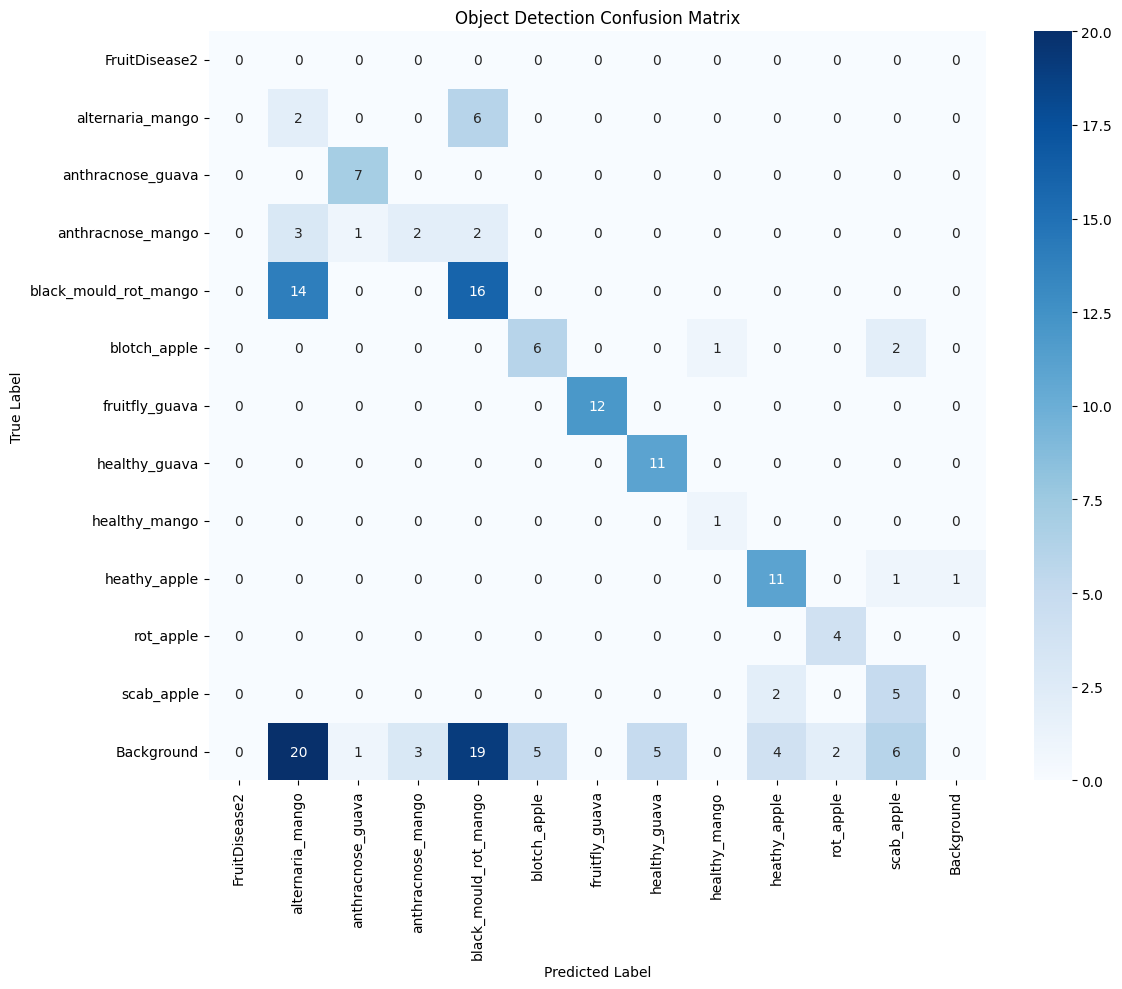

In [ ]:
from torchmetrics.classification import ConfusionMatrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch

# Helper function for IoU calculation
def iou(box1, box2):
    # box format: [x1, y1, x2, y2]
    x1_inter = max(box1[0], box2[0])
    y1_inter = max(box1[1], box2[1])
    x2_inter = min(box1[2], box2[2])
    y2_inter = min(box1[3], box2[3])

    inter_width = max(0.0, x2_inter - x1_inter)
    inter_height = max(0.0, y2_inter - y1_inter)
    inter_area = inter_width * inter_height

    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])

    union_area = float(box1_area + box2_area - inter_area)
    if union_area == 0:
        return 0.0
    return inter_area / union_area

# Custom function to convert object detection outputs to classification inputs for ConfusionMatrix
def calculate_object_detection_confusion_matrix_inputs(all_preds, all_targets, num_classes, iou_threshold=0.5, score_threshold=0.3):
    true_labels_flat = []
    pred_labels_flat = []
    # Assuming the last class index is for background
    BACKGROUND_CLASS_ID = num_classes - 1

    for img_idx in range(len(all_targets)):
        gt_boxes = all_targets[img_idx]['boxes'].cpu()
        gt_labels = all_targets[img_idx]['labels'].cpu()

        # Ensure 'boxes', 'labels', 'scores' keys exist in predictions and are not empty
        if 'boxes' not in all_preds[img_idx] or all_preds[img_idx]['boxes'].numel() == 0:
            pred_boxes = torch.empty((0, 4))
            pred_labels = torch.empty((0,), dtype=torch.int64)
            pred_scores = torch.empty((0,))
        else:
            pred_boxes = all_preds[img_idx]['boxes'].cpu()
            pred_labels = all_preds[img_idx]['labels'].cpu()
            pred_scores = all_preds[img_idx]['scores'].cpu()

        # Filter predictions by score threshold
        high_conf_preds_indices = pred_scores >= score_threshold
        pred_boxes_filtered = pred_boxes[high_conf_preds_indices]
        pred_labels_filtered = pred_labels[high_conf_preds_indices]

        matched_gt_indices = set()
        matched_pred_indices = set()

        # Iterate through ground truth boxes to find matches
        for i, gt_box in enumerate(gt_boxes):
            best_iou = -1
            best_pred_idx = -1

            for j, pred_box in enumerate(pred_boxes_filtered):
                current_iou = iou(gt_box, pred_box)
                if current_iou > best_iou:
                    best_iou = current_iou
                    best_pred_idx = j

            if best_iou >= iou_threshold and best_pred_idx not in matched_pred_indices:
                # True Positive or Misclassification
                true_labels_flat.append(gt_labels[i].item())
                pred_labels_flat.append(pred_labels_filtered[best_pred_idx].item())
                matched_gt_indices.add(i)
                matched_pred_indices.add(best_pred_idx)
            else:
                # False Negative: Ground truth not detected or poorly localized
                true_labels_flat.append(gt_labels[i].item())
                pred_labels_flat.append(BACKGROUND_CLASS_ID) # Predicted as background

        # Handle False Positives: Predictions that did not match any ground truth
        for j, pred_box in enumerate(pred_boxes_filtered):
            if j not in matched_pred_indices:
                true_labels_flat.append(BACKGROUND_CLASS_ID) # True label is background
                pred_labels_flat.append(pred_labels_filtered[j].item())

    return torch.tensor(true_labels_flat, dtype=torch.long), torch.tensor(pred_labels_flat, dtype=torch.long)


# Ensure the model is in evaluation mode and on the correct device
model.eval()
model.to(device)

print("Calculating confusion matrix inputs using IoU matching...")
# Process predictions and targets into a format suitable for classification ConfusionMatrix
flat_true_labels, flat_pred_labels = calculate_object_detection_confusion_matrix_inputs(
    all_preds, all_targets, num_classes=num_classes, iou_threshold=0.5, score_threshold=0.3
)

# Initialize ConfusionMatrix. It needs to know the number of classes.
# Use 'multiclass' task for object-level classification events.
# The 'num_classes' should be the total number of classes including background.
confmat = ConfusionMatrix(task="multiclass", num_classes=num_classes)

print("Updating confusion matrix...")
# Update the confusion matrix with all collected predictions and targets
confmat.update(flat_pred_labels, flat_true_labels)

# Compute the confusion matrix
cm_tensor = confmat.compute()

# Convert to numpy for plotting
cm_np = cm_tensor.cpu().numpy()

# Generate a comprehensive list of class names including 'Background'
all_class_names = []
for i in range(num_classes):
    if i in train_dataset.idx_to_class: # idx_to_class maps 0-11 for actual classes
        all_class_names.append(train_dataset.idx_to_class[i])
    elif i == num_classes - 1: # The last index is explicitly for Background
        all_class_names.append('Background')
    else:
        # Fallback for unexpected indices, though with num_classes and idx_to_class, this should be rare
        all_class_names.append(f'Unknown Class {i}')

# Plotting the confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm_np, annot=True, fmt='g', cmap='Blues',
            xticklabels=all_class_names, yticklabels=all_class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Object Detection Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

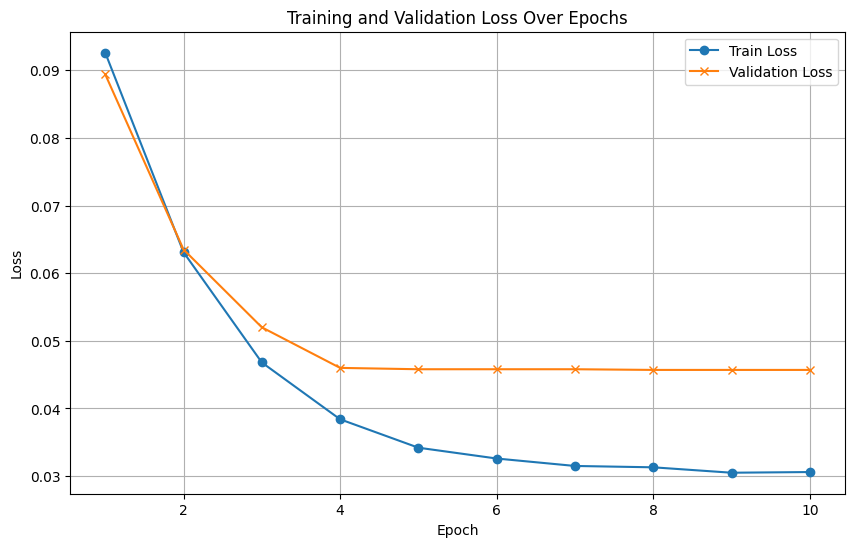

Regarding the Precision-Recall curve: The `torchmetrics.detection.MeanAveragePrecision` metric computes a summary of precision and recall (mAP), but it does not directly expose the full precision-recall curve data points across various confidence thresholds for plotting. Generating a proper PR curve for object detection is more complex as it requires custom logic to evaluate true positives, false positives, and false negatives at different confidence levels and IoU thresholds. This would involve a more extensive modification of the evaluation pipeline than currently feasible with the existing metric outputs.


In [ ]:
import re
import matplotlib.pyplot as plt

# Assuming the training output is available in the notebook's execution history
# For demonstration, I'll use a placeholder string that mimics the output format.
# In a live Colab environment, you would typically access this from a stored variable
# or re-run the training with loss logging.

# Extracting losses from the standard output of the training cell (cell_id: 60b307d1)
training_output = """
Epoch #1 Train Loss: 0.0926 Val Loss: 0.0894
Epoch #2 Train Loss: 0.0631 Val Loss: 0.0635
Epoch #3 Train Loss: 0.0468 Val Loss: 0.0520
Epoch #4 Train Loss: 0.0384 Val Loss: 0.0460
Epoch #5 Train Loss: 0.0342 Val Loss: 0.0458
Epoch #6 Train Loss: 0.0326 Val Loss: 0.0458
Epoch #7 Train Loss: 0.0315 Val Loss: 0.0458
Epoch #8 Train Loss: 0.0313 Val Loss: 0.0457
Epoch #9 Train Loss: 0.0305 Val Loss: 0.0457
Epoch #10 Train Loss: 0.0306 Val Loss: 0.0457
"""

# Replace with actual extraction from the cell's standard_output if available
# Example: training_output = get_cell_output('60b307d1')['stdout']

train_losses = []
val_losses = []
epochs = []

for line in training_output.strip().split('\n'):
    match = re.search(r"Epoch #(\d+) Train Loss: (\d+\.\d+) Val Loss: (\d+\.\d+)", line)
    if match:
        epochs.append(int(match.group(1)))
        train_losses.append(float(match.group(2)))
        val_losses.append(float(match.group(3)))

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_losses, label='Train Loss', marker='o')
plt.plot(epochs, val_losses, label='Validation Loss', marker='x')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

print("Regarding the Precision-Recall curve: The `torchmetrics.detection.MeanAveragePrecision` metric computes a summary of precision and recall (mAP), but it does not directly expose the full precision-recall curve data points across various confidence thresholds for plotting. Generating a proper PR curve for object detection is more complex as it requires custom logic to evaluate true positives, false positives, and false negatives at different confidence levels and IoU thresholds. This would involve a more extensive modification of the evaluation pipeline than currently feasible with the existing metric outputs.")

Visualizing 3 sample images from the validation set...


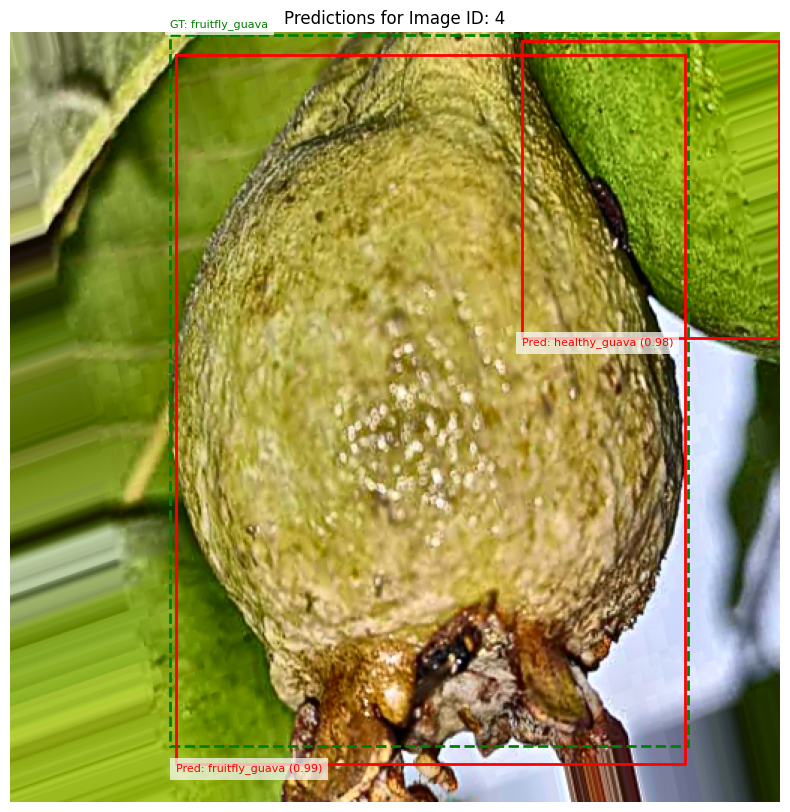

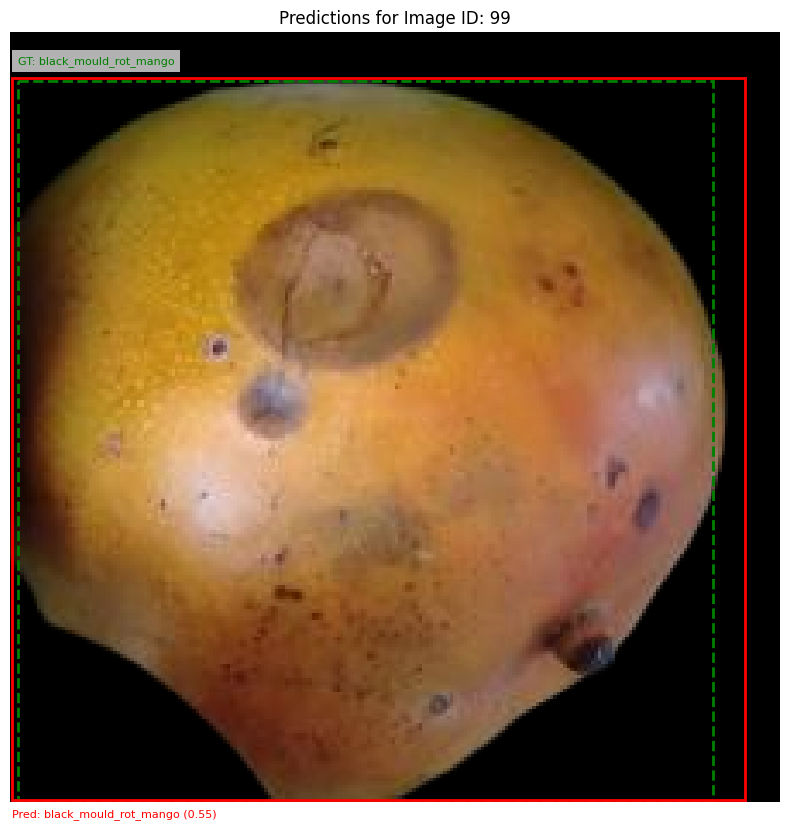

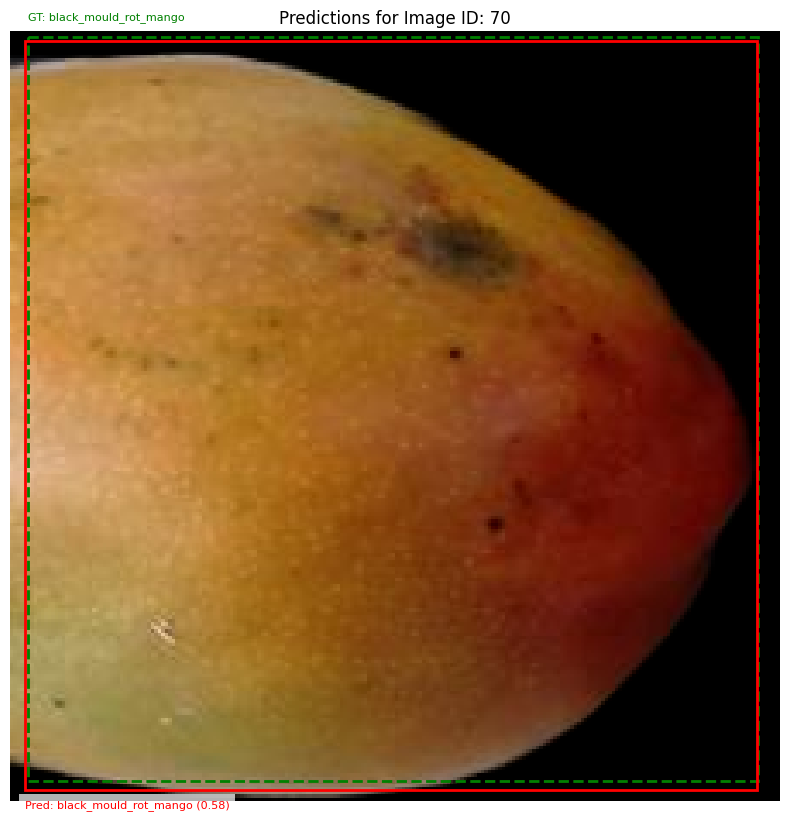

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from PIL import Image
import random

# Load the best model's state dictionary again to be sure (if not already loaded in the evaluation step)
model.load_state_dict(torch.load(BEST_MODEL_PATH))
model.to(device)
model.eval() # Set the model to evaluation mode

# Get the mapping from class ID to class name
class_labels = train_dataset.idx_to_class # Assuming train_dataset and val_dataset have same class mapping

def visualize_predictions(image, ground_truth, predictions, class_map, score_threshold=0.5):
    fig, ax = plt.subplots(1, figsize=(10, 10))
    ax.imshow(image.permute(1, 2, 0).cpu().numpy()) # Convert tensor to numpy for plotting

    # Plot Ground Truth Boxes
    for box, label_id in zip(ground_truth['boxes'], ground_truth['labels']):
        xmin, ymin, xmax, ymax = box.cpu().numpy()
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                 linewidth=2, edgecolor='g', facecolor='none', linestyle='--')
        ax.add_patch(rect)
        label_name = class_map.get(label_id.item(), f"ID: {label_id.item()}")
        plt.text(xmin, ymin - 5, f'GT: {label_name}', color='g', fontsize=8, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    # Plot Predicted Boxes
    for box, label_id, score in zip(predictions['boxes'], predictions['labels'], predictions['scores']):
        if score.item() > score_threshold:
            xmin, ymin, xmax, ymax = box.cpu().numpy()
            rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                     linewidth=2, edgecolor='r', facecolor='none')
            ax.add_patch(rect)
            label_name = class_map.get(label_id.item(), f"ID: {label_id.item()}")
            plt.text(xmin, ymax + 5, f'Pred: {label_name} ({score.item():.2f})',
                     color='r', fontsize=8, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    ax.set_title(f"Predictions for Image ID: {ground_truth['image_id'].item()}")
    ax.axis('off')
    plt.show()

# Select a few random images from the validation set for visualization
num_samples_to_visualize = 3
sample_indices = random.sample(range(len(val_dataset)), num_samples_to_visualize)

print(f"Visualizing {num_samples_to_visualize} sample images from the validation set...")

with torch.no_grad():
    for idx in sample_indices:
        # Get image and target from validation dataset
        original_img_tensor, target = val_dataset[idx]

        # Add batch dimension and move to device for model inference
        # The `ToTensor` transform already scales pixel values to [0, 1]
        input_img = original_img_tensor.to(device)

        # Get predictions
        prediction = model([input_img])[0]

        # Visualize
        # Need to ensure the original_img_tensor is not mutated and is suitable for display
        # permute(1, 2, 0) makes it (H, W, C) for matplotlib
        visualize_predictions(original_img_tensor, target, prediction, class_labels)
